In [1]:
# Instalar una sola vez: statsmodels (Holt-Winters), xgboost y scikit-learn (XGBoost), streamlit y plotly (dashboard)
# %pip install pandas numpy matplotlib statsmodels xgboost scikit-learn streamlit plotly
# En Mac, XGBoost necesita además OpenMP: en la Terminal, brew install libomp

# 🔷Previsión: resultado 2 (y reparto del resultado 3)
**Objetivo:**
- **Resultado 2 (previsión de la demanda):** prever cuántos kg de chips importará España en los próximos 12 meses. Contrasta H2: *un modelo de machine learning mejora al baseline estacional (seasonal naive) y a Holt-Winters al prever la demanda en kg*.
- **Resultado 3 (reparto):** repartir los kg previstos entre los proveedores mejor puntuados (`proveedores_puntuados.csv`) con un tope del 40 % por país y valorarlo en euros.

**Datos:** `hechos_origen` (Datacomex, país de origen) y `dim_producto`, de `datos/procesados`. Serie mensual de kg de chips con `peso_kg_serie` (sin las filas de peso anómalo). Supuesto: importaciones ≈ demanda (España casi no fabrica chips).

**Periodo (decisión 2.9):** los modelos se entrenan con enero 2015 – diciembre 2025 y prevén 2026. Los meses reales de enero a agosto de 2026 (provisionales) se usan solo como comprobación final.

**Método:** tres modelos (seasonal naive, Holt-Winters y XGBoost), comparados con el error MASE en un origen móvil (*rolling origin*).

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

pd.set_option("display.float_format", "{:,.2f}".format)
PROC = Path("datos/procesados")

# Lectura de las tablas del modelo: códigos como texto y solo lo vacío como NaN ("NA" = Namibia se mantiene)
CODIGOS = {"id_pais": str, "partner": str, "codigo": str, "familia": str, "partida": str}

def leer(nombre):
    ruta = PROC / f"{nombre}.csv"
    columnas = pd.read_csv(ruta, nrows=0).columns
    return pd.read_csv(ruta, dtype=CODIGOS, keep_default_na=False, na_values=[""],
                       parse_dates=["fecha"] if "fecha" in columnas else False)

## ✅Paso 0. Serie mensual de kg de chips
**Enunciado:** Construir la serie mensual de kg importados de chips (todos los países de origen) con `peso_kg_serie`, y separarla en entrenamiento (2015–2025) y comprobación (enero–agosto 2026).

- Se suman **todos los orígenes**, también los no especificados (de media, el 0.16 % de los kg al mes), porque la demanda es el total importado.
- Las filas con peso anómalo no suman kg (su `peso_kg_serie` está vacío); su valor en euros sí se mantiene en la tabla.

In [3]:
FIN_ENTRENAMIENTO = "2025-12-01"     # años completos 2015-2025 (decisión 2.9)

hechos_origen = leer("hechos_origen")
dim_producto = leer("dim_producto")

chips = hechos_origen.merge(dim_producto[["codigo", "bloque"]], on="codigo")
chips = chips[chips["bloque"] == "chips"]

# kg por mes (suma de todos los orígenes; las filas con peso anómalo no suman)
serie = chips.groupby("fecha")["peso_kg_serie"].sum().asfreq("MS")

entrenamiento = serie[:FIN_ENTRENAMIENTO]
comprobacion = serie["2026-01-01":]

print(f"Serie completa: {serie.index.min():%Y-%m} a {serie.index.max():%Y-%m} "
      f"({len(serie)} meses, {serie.isna().sum()} vacíos)")
print(f"Entrenamiento: {len(entrenamiento)} meses | Comprobación (2026): {len(comprobacion)} meses")

# Total por año (millones de kg)
(entrenamiento.groupby(entrenamiento.index.year).sum() / 1e6).rename("millones_kg").to_frame().T

Serie completa: 2015-01 a 2026-08 (140 meses, 0 vacíos)
Entrenamiento: 132 meses | Comprobación (2026): 8 meses


fecha,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
millones_kg,14.25,12.37,7.55,11.12,13.24,13.04,15.40,43.88,31.42,31.63,17.02


**📌Conclusión:**
- Serie de 140 meses (enero 2015 – agosto 2026), sin meses vacíos: 132 para entrenar (2015–2025) y 8 para comprobar (enero–agosto 2026).
- Los kg anuales son estables hasta 2021 (7.55–15.40 millones), suben con fuerza en 2022–2024 (43.88, 31.42 y 31.63 millones: acopio tras la crisis de chips) y bajan en 2025 (17.02 millones).

## ✅Paso 1. Cómo es la serie
**Enunciado:** Dibujar la serie mensual de kg para ver su nivel, tendencia, estacionalidad y cambios bruscos antes de elegir los modelos.

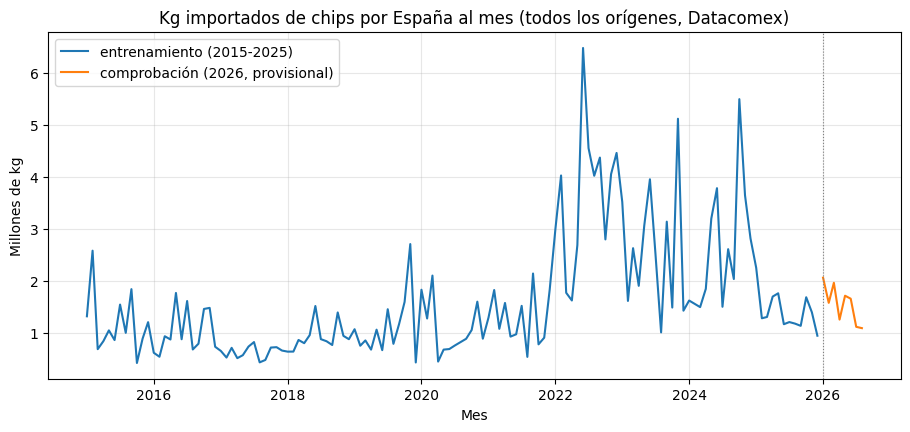

In [4]:
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(entrenamiento.index, entrenamiento / 1e6, label="entrenamiento (2015-2025)")
ax.plot(comprobacion.index, comprobacion / 1e6, color="tab:orange", label="comprobación (2026, provisional)")
ax.axvline(pd.Timestamp("2026-01-01"), color="grey", linestyle=":", linewidth=0.8)
ax.set_title("Kg importados de chips por España al mes (todos los orígenes, Datacomex)")
ax.set_xlabel("Mes")
ax.set_ylabel("Millones de kg")
ax.legend()
ax.grid(alpha=0.3)
plt.show()

**📌Conclusión:**
- La serie tiene **tres etapas**: nivel bajo y estable hasta 2021, un salto de nivel en 2022–2024 y una vuelta a un nivel más bajo en 2025, que se mantiene en 2026.
- Hay **picos puntuales** (p. ej. junio 2022: 6.49 millones de kg; octubre 2024: 5.50 millones), que son ruido difícil de prever.
- **Para los modelos:** la estacionalidad es de 12 meses, pero los cambios de nivel dificultan prever a 12 meses. Es una limitación del resultado 2.

## ✅Paso 2. Cómo se evalúan los modelos y modelo de referencia (seasonal naive)
**Enunciado:** Definir el error y el método de evaluación comunes a todos los modelos, y calcular el modelo de referencia.

- **MASE** (*mean absolute scaled error*): error absoluto medio de la previsión dividido por el error medio de repetir el valor de hace 12 meses dentro del entrenamiento. MASE < 1: mejor que esa referencia; > 1: peor. Sirve para comparar modelos sin depender de la escala de los kg (Hyndman y Koehler, 2006).
- **Origen móvil (rolling origin):** se simula prever en varios momentos del pasado. En cada origen se entrena con los datos hasta ese mes y se prevén los 12 meses siguientes. 9 orígenes, cada 3 meses, de diciembre 2022 a diciembre 2024 (el último prevé 2025 entero), siempre dentro de 2015–2025.
- **Seasonal naive (referencia):** cada mes previsto = el mismo mes del año anterior. Cualquier modelo útil tiene que mejorarlo.

In [5]:
M = 12        # periodo estacional (meses)
H = 12        # horizonte de previsión (meses)
ORIGENES = pd.date_range("2022-12-01", "2024-12-01", freq="3MS")   # 9 orígenes

def mase(real, prevision, train, m=M):
    """Error absoluto medio escalado por el error del seasonal naive dentro del entrenamiento."""
    escala = np.mean(np.abs(train.values[m:] - train.values[:-m]))
    return np.mean(np.abs(np.asarray(real) - np.asarray(prevision))) / escala

def seasonal_naive(train, h):
    """Cada mes previsto = el mismo mes del año anterior."""
    return np.resize(train.iloc[-M:].values, h)

def evaluar(modelo, serie_train=entrenamiento, origenes=ORIGENES, h=H):
    """Origen móvil: entrena hasta cada origen, prevé los h meses siguientes y calcula el MASE."""
    filas = []
    for origen in origenes:
        train = serie_train[:origen]
        test = serie_train[origen + pd.offsets.MonthBegin(1):].iloc[:h]
        prevision = modelo(train, len(test))
        filas.append({"origen": origen.strftime("%Y-%m"), "meses_test": len(test),
                      "mase": mase(test, prevision, train)})
    return pd.DataFrame(filas).set_index("origen")

resultados = {"seasonal_naive": evaluar(seasonal_naive)}
print(f"MASE medio del seasonal naive: {resultados['seasonal_naive']['mase'].mean():.2f}")
resultados["seasonal_naive"]

MASE medio del seasonal naive: 1.54


,meses_test,mase
origen,,
2022-12,12,2.05
2023-03,12,1.93
2023-06,12,1.61
2023-09,12,1.27
2023-12,12,1.37
2024-03,12,1.17
2024-06,12,1.58
2024-09,12,1.45
2024-12,12,1.48


**📌Conclusión:**
- El seasonal naive tiene un MASE medio de **1.54** en el origen móvil: se equivoca un 54 % más que su error dentro del entrenamiento, por los cambios de nivel.
- El peor origen es diciembre 2022 (2.05): prevé 2023 copiando 2022, el año de acopio. El mejor es marzo 2024 (1.17).
- Es el **listón mínimo**: Holt-Winters y XGBoost tienen que bajar de 1.54 para ser útiles.

## ✅Paso 3. Holt-Winters
**Enunciado:** Prever los kg con Holt-Winters (suavizado exponencial con nivel, tendencia y estacionalidad de 12 meses) y evaluarlo con el mismo origen móvil y el MASE.

- **Logaritmo:** el modelo se ajusta sobre log(kg) para reducir el efecto de los picos; la previsión se devuelve a kg con la exponencial (nunca sale negativa).
- **Tendencia amortiguada:** la tendencia se frena con el tiempo y no se proyecta sin fin (Hyndman y Athanasopoulos, 2021).
- **Comparación de variantes:** con y sin logaritmo, y con tendencia amortiguada, sin amortiguar o sin tendencia, para justificar la elección.

In [6]:
import warnings
from statsmodels.tsa.holtwinters import ExponentialSmoothing

def holt_winters(train, h, tendencia="add", amortiguada=True, log=True):
    """Holt-Winters: nivel + tendencia + estacionalidad (12 meses), con más peso a los meses recientes."""
    y = np.log(train) if log else train
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")          # avisos de convergencia del ajuste
        ajuste = ExponentialSmoothing(y, trend=tendencia, damped_trend=amortiguada,
                                      seasonal="add", seasonal_periods=M).fit()
    prevision = ajuste.forecast(h)
    return np.exp(prevision).values if log else prevision.values

# Variantes: con y sin logaritmo, con tendencia amortiguada, sin amortiguar y sin tendencia
VARIANTES_HW = {
    "log + tendencia amortiguada": dict(tendencia="add", amortiguada=True, log=True),
    "log + tendencia sin amortiguar": dict(tendencia="add", amortiguada=False, log=True),
    "log + sin tendencia": dict(tendencia=None, amortiguada=False, log=True),
    "sin log + tendencia amortiguada": dict(tendencia="add", amortiguada=True, log=False),
}
comparacion_hw = pd.Series({nombre: evaluar(lambda tr, h, p=params: holt_winters(tr, h, **p))["mase"].mean()
                            for nombre, params in VARIANTES_HW.items()}, name="mase_medio")
comparacion_hw.sort_values().to_frame()

,mase_medio
log + sin tendencia,1.37
log + tendencia amortiguada,1.39
sin log + tendencia amortiguada,1.48
log + tendencia sin amortiguar,1.68


In [7]:
resultados["holt_winters"] = evaluar(holt_winters)      # variante elegida: log + tendencia amortiguada

comparacion = pd.DataFrame({modelo: r["mase"] for modelo, r in resultados.items()})
print("MASE medio:", comparacion.mean().round(2).to_dict())
comparacion

MASE medio: {'seasonal_naive': 1.54, 'holt_winters': 1.39}


,seasonal_naive,holt_winters
origen,,
2022-12,2.05,2.00
2023-03,1.93,1.28
2023-06,1.61,1.39
2023-09,1.27,1.14
2023-12,1.37,1.19
2024-03,1.17,1.30
2024-06,1.58,1.24
2024-09,1.45,1.15
2024-12,1.48,1.84


**📌Conclusión:**
- **Elección de la variante:** logaritmo + tendencia amortiguada (MASE medio 1.39). Sin tendencia sale casi igual (1.37); se mantiene la tendencia amortiguada para conservar el modelo completo (nivel, tendencia y estacionalidad). El logaritmo mejora el resultado (1.48 sin él) y la tendencia sin amortiguar es la peor (1.68): proyecta las subidas y bajadas sin fin.
- **Frente al seasonal naive:** Holt-Winters baja el MASE medio de 1.54 a **1.39** y gana en 7 de los 9 orígenes.
- Pierde en marzo 2024 (1.30 frente a 1.17) y en diciembre 2024 (1.84 frente a 1.48). Al prever 2025, la tendencia aprendida en 2022–2024 todavía empuja hacia arriba y no recoge la bajada de 2025.
- Sigue por encima de 1: los cambios de nivel de la serie limitan la precisión de cualquier modelo a 12 meses.

## ✅Paso 4. XGBoost (machine learning)
**Enunciado:** Prever los kg con XGBoost (árboles de decisión con *boosting*; Chen y Guestrin, 2016) y evaluarlo con el mismo origen móvil y el MASE.

- **Variables:** la serie se convierte en una tabla: kg de hace 1, 2, 3, 6 y 12 meses (retardos), media de los 3 meses anteriores y mes del año. Se trabaja con log(kg), como en Holt-Winters.
- **Previsión recursiva:** se prevé mes a mes; cada previsión se usa como dato para prever el mes siguiente.
- **Parámetros fijos y prudentes** (300 árboles de profundidad 3, tasa de aprendizaje 0.05): con unos 120 meses de entrenamiento, ajustarlos con los mismos datos de la evaluación llevaría a sobreajuste.

In [8]:
from xgboost import XGBRegressor

RETARDOS = [1, 2, 3, 6, 12]          # kg de hace 1, 2, 3, 6 y 12 meses

def variables(y):
    """Tabla de variables explicativas para cada mes: retardos, media de los 3 meses anteriores y mes del año."""
    X = pd.DataFrame(index=y.index)
    for r in RETARDOS:
        X[f"retardo_{r}"] = y.shift(r)
    X["media_3_meses"] = y.shift(1).rolling(3).mean()
    X["mes"] = y.index.month
    return X

def xgboost(train, h):
    """XGBoost sobre log(kg); prevé mes a mes usando sus propias previsiones como retardos (recursivo)."""
    y = np.log(train)
    X = variables(y).dropna()
    modelo = XGBRegressor(n_estimators=300, max_depth=3, learning_rate=0.05, subsample=0.8, random_state=42)
    modelo.fit(X, y.loc[X.index])

    historia = y.copy()
    previsiones = []
    for _ in range(h):
        mes_siguiente = historia.index[-1] + pd.offsets.MonthBegin(1)
        historia.loc[mes_siguiente] = np.nan                       # hueco para el mes a prever
        x = variables(historia).iloc[[-1]]
        historia.loc[mes_siguiente] = modelo.predict(x)[0]         # la previsión pasa a ser historia
        previsiones.append(historia.loc[mes_siguiente])
    return np.exp(np.array(previsiones))

resultados["xgboost"] = evaluar(xgboost)

comparacion = pd.DataFrame({modelo: r["mase"] for modelo, r in resultados.items()})
print("MASE medio:", comparacion.mean().round(2).to_dict())
comparacion

MASE medio: {'seasonal_naive': 1.54, 'holt_winters': 1.39, 'xgboost': 1.47}


,seasonal_naive,holt_winters,xgboost
origen,,,
2022-12,2.05,2.00,1.81
2023-03,1.93,1.28,1.27
2023-06,1.61,1.39,1.40
2023-09,1.27,1.14,1.39
2023-12,1.37,1.19,1.79
2024-03,1.17,1.30,1.66
2024-06,1.58,1.24,1.10
2024-09,1.45,1.15,1.22
2024-12,1.48,1.84,1.58


**📌Conclusión:**
- XGBoost tiene un MASE medio de **1.47**: mejora al seasonal naive (1.54), pero **no a Holt-Winters (1.39)**.
- Es el modelo más irregular entre orígenes (de 1.10 a 1.81). Gana al naive en 5 de los 9 orígenes y a Holt-Winters en 4. Es el mejor al prever 2023 desde diciembre 2022 (1.81) y desde junio 2024 (1.10), pero el peor en 2023-12 y 2024-03.
- Motivos: con unos 120 meses hay pocos datos para machine learning, y la previsión recursiva acumula errores (cada mes previsto se usa para prever el siguiente). Además, los árboles de decisión no pueden prever valores fuera del rango que han visto, así que les cuesta seguir los cambios de nivel.
- **Para H2 (en el origen móvil):** el machine learning no mejora al modelo estadístico clásico. Falta la comprobación con 2026.

## ✅Paso 4b. Prueba documentada: XGBoost + índice de precios de importación (IPRIM)
**Enunciado:** Probar si el índice de precios de importación del INE (base 2021, división 26) mejora a XGBoost como variable explicativa. El modelo principal no cambia.

- **Sin fuga de información:** se usa el IPRIM de **hace 12 meses**, porque al prever 2026 no se conocen los precios de 2026. Usar los reales sería dar al modelo información del futuro.
- **Tres formas:** nivel del índice, variación anual y las dos juntas; se comparan con XGBoost sin IPRIM en el origen móvil y en 2026.
- El IPRIM se lee de `datos/raw` (quedó fuera del modelo de datos el 9 nov); no se modifica.

In [9]:
# IPRIM (INE, base 2021, división 26): se lee de datos/raw porque quedó fuera del modelo de datos (9 nov)
iprim_raw = pd.read_csv(Path("datos/raw") / "indice_precios_ine.csv", sep=";", dtype=str)
iprim_raw = iprim_raw[(iprim_raw["Tipo de operación de precios industriales"] == "Total")
                      & (iprim_raw["Índice y tasas"] == "Índice")]
iprim = pd.Series(iprim_raw["Total"].str.replace(",", ".").astype(float).values,
                  index=pd.to_datetime(iprim_raw["Periodo"].str.replace("M", "-") + "-01"),
                  name="iprim").sort_index()
usado = iprim["2014-01-01":]       # periodo que usa el modelo (2015-2025 con 12 meses de retraso)
print(f"IPRIM: {iprim.index.min():%Y-%m} a {iprim.index.max():%Y-%m} | usado 2014-2026: "
      f"mínimo {usado.min():.2f}, máximo {usado.max():.2f}")
# Correlación de Spearman entre el log(kg) y el IPRIM del mismo mes (2015-2025)
juntos = pd.concat([np.log(entrenamiento), iprim], axis=1, join="inner")
print(f"Spearman log(kg) - IPRIM: {juntos.corr(method='spearman').iloc[0, 1]:.2f}")

def xgboost_iprim(train, h, nivel=True, variacion=False):
    """XGBoost con el IPRIM de hace 12 meses (ya conocido al prever 12 meses: sin fuga de información)."""
    def variables_iprim(y):
        X = variables(y)
        if nivel:
            X["iprim_hace_12"] = iprim.shift(12).reindex(X.index)
        if variacion:
            X["iprim_var_anual_hace_12"] = (iprim / iprim.shift(12) - 1).shift(12).reindex(X.index)
        return X
    y = np.log(train)
    X = variables_iprim(y).dropna()
    modelo = XGBRegressor(n_estimators=300, max_depth=3, learning_rate=0.05, subsample=0.8, random_state=42)
    modelo.fit(X, y.loc[X.index])
    historia = y.copy()
    previsiones = []
    for _ in range(h):
        mes_siguiente = historia.index[-1] + pd.offsets.MonthBegin(1)
        historia.loc[mes_siguiente] = np.nan
        historia.loc[mes_siguiente] = modelo.predict(variables_iprim(historia).iloc[[-1]])[0]
        previsiones.append(historia.loc[mes_siguiente])
    return np.exp(np.array(previsiones))

VARIANTES_IPRIM = {
    "sin IPRIM (modelo principal)": None,
    "IPRIM nivel": dict(nivel=True, variacion=False),
    "IPRIM variación anual": dict(nivel=False, variacion=True),
    "IPRIM nivel + variación": dict(nivel=True, variacion=True),
}
prueba_iprim = {}
for nombre, params in VARIANTES_IPRIM.items():
    modelo = xgboost if params is None else (lambda tr, h, p=params: xgboost_iprim(tr, h, **p))
    prevision = modelo(entrenamiento, H)[:len(comprobacion)]
    prueba_iprim[nombre] = {"mase_origen_movil": evaluar(modelo)["mase"].mean(),
                            "mase_2026": mase(comprobacion, prevision, entrenamiento),
                            "error_total_2026_%": (prevision.sum() / comprobacion.sum() - 1) * 100}
pd.DataFrame(prueba_iprim).T

IPRIM: 2005-01 a 2026-09 | usado 2014-2026: mínimo 99.06, máximo 107.87
Spearman log(kg) - IPRIM: 0.44


,mase_origen_movil,mase_2026,error_total_2026_%
sin IPRIM (modelo principal),1.47,0.31,-12.90
IPRIM nivel,1.40,0.31,-18.63
IPRIM variación anual,1.64,0.33,-12.01
IPRIM nivel + variación,1.49,0.25,-13.62


**📌Conclusión:**
- Con el nivel del IPRIM, XGBoost mejora en el origen móvil (1.47 → 1.40), pero se queda más corto en el total de 2026 (−18.63 % frente a −12.90 %). Con la variación anual empeora (1.64). **La mejora es pequeña y no consistente.**
- Motivos: el IPRIM mide toda la división 26 (ordenadores, móviles, óptica), no solo chips, y casi no varía (99.06–107.87 en 2014–2026). La correlación con los kg (Spearman 0.44) puede ser casual, porque los dos suben a la vez en 2022. Además, quedarse con la mejor de varias variantes inflaría el resultado (*data snooping*).
- **No entra en el modelo principal.** Apoya la explicación de H2: sin variables explicativas específicas, el machine learning no supera a los métodos clásicos.

## ✅Paso 5. Combinación de los tres modelos
**Enunciado:** Prever con la media simple de los tres modelos (seasonal naive, Holt-Winters y XGBoost) y evaluarla con el mismo origen móvil. Al combinar, los errores de cada modelo se compensan; en la competición M4, 12 de los 17 métodos más precisos eran combinaciones (Makridakis et al., 2018).

In [10]:
def combinacion(train, h):
    """Media simple de las previsiones de los tres modelos."""
    return (seasonal_naive(train, h) + holt_winters(train, h) + xgboost(train, h)) / 3

resultados["combinacion"] = evaluar(combinacion)

comparacion = pd.DataFrame({modelo: r["mase"] for modelo, r in resultados.items()})
print("MASE medio:", comparacion.mean().round(2).to_dict())
comparacion

MASE medio: {'seasonal_naive': 1.54, 'holt_winters': 1.39, 'xgboost': 1.47, 'combinacion': 1.32}


,seasonal_naive,holt_winters,xgboost,combinacion
origen,,,,
2022-12,2.05,2.00,1.81,1.79
2023-03,1.93,1.28,1.27,1.04
2023-06,1.61,1.39,1.40,1.42
2023-09,1.27,1.14,1.39,1.18
2023-12,1.37,1.19,1.79,1.35
2024-03,1.17,1.30,1.66,1.17
2024-06,1.58,1.24,1.10,1.17
2024-09,1.45,1.15,1.22,1.16
2024-12,1.48,1.84,1.58,1.59


**📌Conclusión:**
- La combinación tiene el mejor MASE medio en el origen móvil: **1.32**, frente a 1.39 de Holt-Winters, 1.47 de XGBoost y 1.54 del naive.
- Es más estable que cada modelo por separado: nunca es la peor y gana a Holt-Winters en 5 de los 9 orígenes (p. ej. marzo 2023: 1.04 frente a 1.28).

## ✅Paso 6. Comprobación con enero–agosto 2026
**Enunciado:** Entrenar cada modelo (y la combinación) con toda la serie 2015–2025, prever los 12 meses de 2026 y comparar enero–agosto con los kg reales (datos que ningún modelo ha visto; provisionales). Se mide el MASE mes a mes y el error del total de kg.

In [11]:
MODELOS = {"seasonal_naive": seasonal_naive, "holt_winters": holt_winters,
           "xgboost": xgboost, "combinacion": combinacion}

# Cada modelo se entrena con 2015-2025 completo y prevé los 12 meses de 2026
previsiones_2026 = pd.DataFrame({nombre: modelo(entrenamiento, H) for nombre, modelo in MODELOS.items()},
                                index=pd.date_range("2026-01-01", periods=H, freq="MS"))

# Comprobación con los meses reales disponibles (enero-agosto 2026)
meses_reales = previsiones_2026.loc[comprobacion.index]
comprobacion_2026 = pd.DataFrame({
    "mase_origen_movil": comparacion.mean(),
    "mase_2026": {m: mase(comprobacion, meses_reales[m], entrenamiento) for m in MODELOS},
    "kg_previstos_ene_ago": meses_reales.sum() / 1e6,
    "kg_reales_ene_ago": comprobacion.sum() / 1e6,
})
comprobacion_2026["error_total_%"] = (comprobacion_2026["kg_previstos_ene_ago"]
                                      / comprobacion_2026["kg_reales_ene_ago"] - 1) * 100
comprobacion_2026

,mase_origen_movil,mase_2026,kg_previstos_ene_ago,kg_reales_ene_ago,error_total_%
seasonal_naive,1.54,0.31,11.86,12.45,-4.72
holt_winters,1.39,0.48,9.32,12.45,-25.14
xgboost,1.47,0.31,10.84,12.45,-12.90
combinacion,1.32,0.30,10.67,12.45,-14.25


**📌Conclusión:**
| Modelo | MASE origen móvil | MASE 2026 | Previstos ene–ago (M kg) | Error del total |
|---|---|---|---|---|
| Seasonal naive | 1.54 | 0.31 | 11.86 | −4.72 % |
| Holt-Winters | 1.39 | 0.48 | 9.32 | −25.14 % |
| XGBoost | 1.47 | 0.31 | 10.84 | −12.90 % |
| **Combinación** | **1.32** | **0.30** | 10.67 | −14.25 % |

- Los MASE de 2026 son bajos porque la escala del MASE incluye los años muy movidos de 2022–2024 y 2026 es un año tranquilo. Se comparan los modelos entre sí, no con 1.
- La **combinación es la mejor mes a mes en las dos evaluaciones**. Holt-Winters, el mejor modelo individual en el origen móvil, es el peor en 2026: se queda un 25 % corto porque la tendencia amortiguada sigue arrastrando la bajada de 2025.
- En el total de enero–agosto, la combinación se queda un 14.25 % corta; el naive acierta más (−4.72 %) porque 2026 se parece mucho a 2025.
- **H2 no se confirma:** XGBoost no mejora a Holt-Winters en el origen móvil (1.47 frente a 1.39) y empata con el naive en 2026. Es coherente con la literatura: con una sola serie corta y sin variables explicativas, el machine learning puro rinde poco (M4; Makridakis et al., 2018). Gana cuando hay muchas series relacionadas y variables explicativas (M5; Makridakis et al., 2022). En las empresas dominan los métodos univariantes simples y el juicio del planificador (Weller y Crone, 2012).

## ✅Paso 7. Previsión final de 2026
**Enunciado:** Tomar la previsión de la combinación (el mejor método en las dos evaluaciones) para los 12 meses de 2026 y compararla con los meses reales disponibles. Es la cantidad que se reparte entre proveedores en el paso 8.

Previsión 2026 (combinación): 16.07 millones de kg (2025 real: 17.02)


,kg_previstos,kg_reales
2026-01-01,"1,652,316.03","2,063,061.26"
2026-02-01,"1,312,118.07","1,578,466.90"
2026-03-01,"1,279,613.15","1,965,163.85"
2026-04-01,"1,270,471.41","1,256,034.64"
2026-05-01,"1,475,364.15","1,715,900.97"
2026-06-01,"1,258,853.38","1,658,451.22"
2026-07-01,"1,294,041.20","1,116,866.85"
2026-08-01,"1,128,706.39","1,091,329.67"
2026-09-01,"1,293,924.82",NaN
2026-10-01,"1,476,798.52",NaN


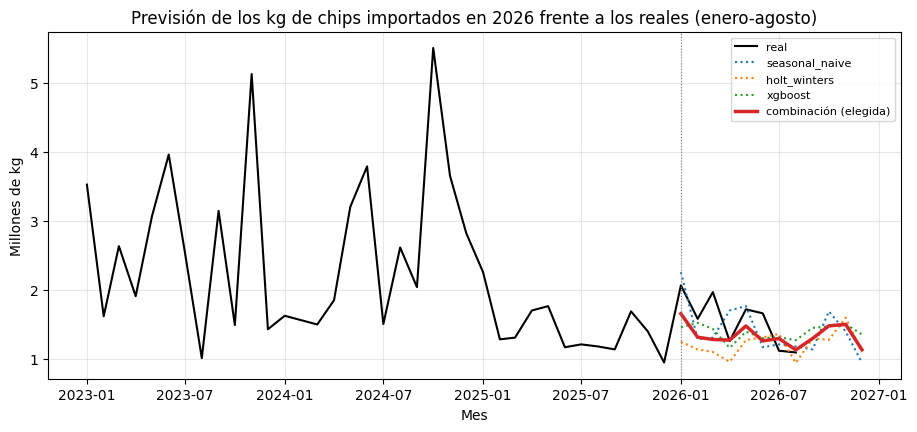

In [12]:
prevision_final = previsiones_2026["combinacion"].rename("kg_previstos")

tabla_prevision = pd.DataFrame({"kg_previstos": prevision_final,
                                "kg_reales": comprobacion.reindex(prevision_final.index)})
print(f"Previsión 2026 (combinación): {prevision_final.sum() / 1e6:,.2f} millones de kg "
      f"(2025 real: {entrenamiento['2025'].sum() / 1e6:,.2f})")
display(tabla_prevision)

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(serie["2023-01-01":].index, serie["2023-01-01":] / 1e6, color="black", label="real")
for nombre in ["seasonal_naive", "holt_winters", "xgboost"]:
    ax.plot(previsiones_2026.index, previsiones_2026[nombre] / 1e6, linestyle=":", label=nombre)
ax.plot(prevision_final.index, prevision_final / 1e6, color="tab:red", linewidth=2.5, label="combinación (elegida)")
ax.axvline(pd.Timestamp("2026-01-01"), color="grey", linestyle=":", linewidth=0.8)
ax.set_title("Previsión de los kg de chips importados en 2026 frente a los reales (enero-agosto)")
ax.set_xlabel("Mes")
ax.set_ylabel("Millones de kg")
ax.legend(fontsize=8)
ax.grid(alpha=0.3)
plt.show()

**📌Conclusión:**
- **Previsión 2026: 16.07 millones de kg** (2025 real: 17.02), entre 1.13 y 1.65 millones al mes.
- En enero–agosto la previsión se queda un 14.25 % corta respecto a lo real: es una cifra **prudente**. En el reparto hay que tenerlo en cuenta (un stock de seguridad lo cubriría; queda como extra si sobra tiempo).
- Esta previsión es la cantidad que se reparte entre los proveedores candidatos en el paso 8.

## ✅Paso 8. Reparto de la demanda prevista entre proveedores (resultado 3)
**Enunciado:** Repartir los kg previstos para 2026 entre los 24 países candidatos (`proveedores_puntuados.csv`) para diversificar y reducir el riesgo, y valorarlo en euros.

- **Regla proporcional a la puntuación:** cada país recibe una parte proporcional a su nota, con dos límites: **40 % de los kg** como máximo (decisión 2.7) y su **capacidad** (kg medios al año que ya envió en 2023–2025). Quien llega a su límite se queda en él y lo sobrante se reparte entre los demás.
- **Valoración:** kg × €/kg mediano de cada país; se comprueba que nadie pasa del 40 % del gasto.
- **Comparación con la situación actual** (los mismos kg con las cuotas reales de 2023–2025): número de países, cuota máxima, concentración (HHI en kg y en €), peso de Asia y coste.
- Se descartó la regla "por orden" (llenar primero al mejor puntuado): concentra todo en la UE y deja a China en 0 %.
- **Limitación:** todos los kg de chips se tratan como intercambiables, aunque cada país vende tipos distintos. Es una propuesta orientativa.

In [13]:
TOPE = 0.40                                       # máximo 40 % de los kg por país (decisión 2.7)
DEMANDA = prevision_final.sum()                   # kg previstos para 2026 (combinación)

proveedores = leer("proveedores_puntuados").set_index("pais")
candidatos = proveedores[proveedores["candidato"]].copy()
candidatos["capacidad_kg"] = candidatos["kg_medio_mes"] * 12      # lo que ya envía al año (2023-2025)
candidatos["limite_kg"] = np.minimum(candidatos["capacidad_kg"], TOPE * DEMANDA)

def reparto_proporcional(c, demanda):
    """Reparte la demanda en proporción a la puntuación; quien llega a su límite se queda en él
    y lo que sobra se vuelve a repartir entre los demás."""
    asignado = pd.Series(0.0, index=c.index)
    libres = list(c.index)
    pendiente = demanda
    while pendiente > 1 and libres:
        parte = c.loc[libres, "puntuacion"] / c.loc[libres, "puntuacion"].sum() * pendiente
        excede = parte > c.loc[libres, "limite_kg"] - asignado[libres]
        if excede.any():                                  # se fija el límite y se repite con el resto
            for pais in parte[excede].index:
                pendiente -= c.loc[pais, "limite_kg"] - asignado[pais]
                asignado[pais] = c.loc[pais, "limite_kg"]
                libres.remove(pais)
        else:
            asignado[libres] += parte
            pendiente = 0
    return asignado

candidatos["kg_propuestos"] = reparto_proporcional(candidatos, DEMANDA)
candidatos["coste_eur"] = candidatos["kg_propuestos"] * candidatos["eur_kg_mediano"]
candidatos["cuota_kg"] = candidatos["kg_propuestos"] / DEMANDA * 100
candidatos["cuota_eur"] = candidatos["coste_eur"] / candidatos["coste_eur"].sum() * 100
candidatos["en_limite"] = np.isclose(candidatos["kg_propuestos"], candidatos["limite_kg"])

print(f"Demanda 2026: {DEMANDA / 1e6:,.2f} M kg | repartido: {candidatos['kg_propuestos'].sum() / 1e6:,.2f} M kg "
      f"entre {(candidatos['kg_propuestos'] > 0).sum()} países")
print(f"Coste del reparto: {candidatos['coste_eur'].sum() / 1e6:,.2f} M€")
print(f"Máxima cuota en kg: {candidatos['cuota_kg'].max():.2f} % | en €: {candidatos['cuota_eur'].max():.2f} % "
      f"(tope {TOPE * 100:.0f} %)")
candidatos.sort_values("kg_propuestos", ascending=False)[
    ["region", "puntuacion", "capacidad_kg", "kg_propuestos", "en_limite", "cuota_kg", "coste_eur", "cuota_eur"]]

Demanda 2026: 16.07 M kg | repartido: 16.07 M kg entre 24 países
Coste del reparto: 1,958.36 M€
Máxima cuota en kg: 24.92 % | en €: 19.35 % (tope 40 %)


,region,puntuacion,capacidad_kg,kg_propuestos,en_limite,cuota_kg,coste_eur,cuota_eur
pais,,,,,,,,
Alemania,UE,86.46,"11,717,877.74","4,005,395.09",False,24.92,"259,901,783.90",13.27
Países Bajos,UE,90.62,"3,397,512.24","3,397,512.24",True,21.14,"379,033,890.54",19.35
Portugal,UE,76.04,"2,133,633.20","2,133,633.20",True,13.28,"121,172,196.49",6.19
China,Asia,42.71,"4,280,012.68","1,978,568.66",False,12.31,"290,343,353.93",14.83
Francia,UE,73.96,"1,154,612.56","1,154,612.56",True,7.18,"138,915,982.17",7.09
Italia,UE,69.79,"1,143,543.26","1,143,543.26",True,7.12,"83,112,093.51",4.24
Japón,Asia,54.17,"445,779.31","445,779.31",True,2.77,"90,100,332.38",4.60
Malasia,Asia,46.88,"400,143.33","400,143.33",True,2.49,"111,465,610.56",5.69
República Checa,UE,77.08,"287,422.79","287,422.79",True,1.79,"50,244,318.04",2.57


In [14]:
# Situación actual: los mismos kg repartidos con las cuotas reales de 2023-2025 (kg medios al mes)
candidatos["kg_actual"] = candidatos["kg_medio_mes"] / candidatos["kg_medio_mes"].sum() * DEMANDA
candidatos["coste_actual_eur"] = candidatos["kg_actual"] * candidatos["eur_kg_mediano"]

def hhi(x):
    """HHI (0-10,000): suma de los cuadrados de las cuotas en %."""
    return ((x / x.sum() * 100) ** 2).sum()

resumen_reparto = pd.DataFrame({
    "situacion_actual": {"paises": (candidatos["kg_actual"] > 0).sum(),
                         "cuota_max_kg_%": candidatos["kg_actual"].max() / DEMANDA * 100,
                         "hhi_kg": hhi(candidatos["kg_actual"]), "hhi_eur": hhi(candidatos["coste_actual_eur"]),
                         "coste_M_eur": candidatos["coste_actual_eur"].sum() / 1e6},
    "propuesta": {"paises": (candidatos["kg_propuestos"] > 0).sum(),
                  "cuota_max_kg_%": candidatos["cuota_kg"].max(),
                  "hhi_kg": hhi(candidatos["kg_propuestos"]), "hhi_eur": hhi(candidatos["coste_eur"]),
                  "coste_M_eur": candidatos["coste_eur"].sum() / 1e6}})
resumen_reparto.loc["cuota_asia_kg_%"] = [
    candidatos.loc[candidatos["region"] == "Asia", col].sum() / DEMANDA * 100 for col in ["kg_actual", "kg_propuestos"]]
print(f"Coste de diversificar: {(resumen_reparto.loc['coste_M_eur', 'propuesta'] / resumen_reparto.loc['coste_M_eur', 'situacion_actual'] - 1) * 100:+.2f} %")
resumen_reparto

Coste de diversificar: +13.66 %


,situacion_actual,propuesta
paises,24.00,24.00
cuota_max_kg_%,44.92,24.92
hhi_kg,"2,571.46","1,521.93"
hhi_eur,"1,544.19","1,008.81"
coste_M_eur,"1,722.99","1,958.36"
cuota_asia_kg_%,21.18,20.06


In [16]:
# Guardar la serie, las previsiones de 2026 y la evaluación de los modelos (para Streamlit)
prevision_guardar = pd.concat([serie.rename("kg_real"), previsiones_2026], axis=1)
prevision_guardar.index.name = "fecha"
prevision_guardar.reset_index().to_csv(PROC / "prevision_2026.csv", index=False)

evaluacion = comprobacion_2026.copy()
evaluacion.index.name = "modelo"
evaluacion.reset_index().to_csv(PROC / "evaluacion_modelos.csv", index=False)
print(f"Guardado: prevision_2026.csv ({len(prevision_guardar)} meses) y evaluacion_modelos.csv ({len(evaluacion)} modelos)")

Guardado: prevision_2026.csv (144 meses) y evaluacion_modelos.csv (4 modelos)


**📌Conclusión:**
- **Propuesta para 2026:** repartir los 16.07 millones de kg previstos entre los **24 países candidatos**. Ninguno pasa del 25 % de los kg (Alemania, 24.92 %) ni del 20 % del gasto (Países Bajos, 19.35 %), muy por debajo del tope del 40 %.
- **22 de los 24 países llegan a su capacidad:** se compra a cada alternativa todo lo que ya ha demostrado poder enviar y el resto se reparte entre Alemania y China, los únicos con capacidad de sobra.
- **Frente a la situación actual:**
  - Alemania pasa del 44.92 % de los kg (hoy ya supera el tope) al 24.92 %.
  - La concentración baja de **muy alta a moderada en kg** (HHI 2,571.46 → 1,521.93) y de moderada a baja en euros (1,544.19 → 1,008.81).
- **Coste de diversificar: +13.66 %** (1,722.99 → 1,958.36 M€). Reducir el riesgo tiene un precio (Tomlin, 2006).
- **El peso de Asia apenas cambia** (21.18 % → 20.06 % de los kg): el reparto diversifica entre países, no entre regiones.
- **H3 se confirma con matices:** hay proveedores alternativos para repartir la demanda y reducir la concentración, pero son pequeños (casi todos llegan a su capacidad) y diversificar encarece la compra.
- **Limitaciones:**
  - Todos los kg de chips se tratan como intercambiables, aunque cada país vende tipos distintos: es una **propuesta orientativa**, no un plan de compras.
  - La capacidad sale de 2023–2025, que incluye años de acopio.
  - El tope del 40 % es un supuesto (en Streamlit se podrá mover).
  - Línea futura: repartir por categoría de producto.

## ✅Paso 8b. Escenarios con tope para Asia y propuesta final
**Enunciado:** El resultado 1 muestra que crece la dependencia de **Asia**, pero el reparto del paso 8 apenas la reduce (reparte entre países, no entre regiones). Repetir el reparto con un tope para Asia (20 %, 15 %, 10 % y 5 % de los kg) y comparar el peso de Asia, la concentración (HHI) y el coste. Elegir un compromiso como propuesta final.

- **Regla:** Asia recibe lo que le tocaría sin tope, como máximo el tope; el resto se reparte entre los países no asiáticos con los mismos límites (40 % por país y capacidad).
- **Propuesta final:** Asia ≤ 15 % (decisión del 17 nov).

In [17]:
def reparto_con_tope_asia(c, demanda, tope_asia):
    """Reparto proporcional con un tope para Asia: Asia recibe lo que le tocaría sin tope, como máximo
    el tope; el resto se reparte entre los países no asiáticos (con los mismos límites por país)."""
    asia = c["region"] == "Asia"
    cupo_asia = min(c.loc[asia, "kg_propuestos"].sum(), tope_asia * demanda)
    asignado = pd.Series(0.0, index=c.index)
    asignado[asia] = reparto_proporcional(c[asia], cupo_asia)
    asignado[~asia] = reparto_proporcional(c[~asia], demanda - cupo_asia)
    return asignado

def resumir(kg, nombre):
    """Indicadores de un reparto: cobertura, peso de Asia, concentración y coste frente a hoy."""
    coste = kg * candidatos["eur_kg_mediano"]
    asia = candidatos["region"] == "Asia"
    return {"escenario": nombre,
            "cubierto_%": kg.sum() / DEMANDA * 100,
            "asia_kg_%": kg[asia].sum() / DEMANDA * 100,
            "asia_eur_%": coste[asia].sum() / coste.sum() * 100,
            "pais_max": kg.idxmax(),
            "cuota_max_kg_%": kg.max() / DEMANDA * 100,
            "hhi_kg": hhi(kg),
            "hhi_eur": hhi(coste),
            "coste_M_eur": coste.sum() / 1e6,
            "coste_frente_a_hoy_%": (coste.sum() / candidatos["coste_actual_eur"].sum() - 1) * 100}

ESCENARIOS_ASIA = [0.20, 0.15, 0.10, 0.05]
escenarios = [resumir(candidatos["kg_actual"], "situación actual"),
              resumir(candidatos["kg_propuestos"], "sin tope para Asia (paso 8)")]
for tope_asia in ESCENARIOS_ASIA:
    escenarios.append(resumir(reparto_con_tope_asia(candidatos, DEMANDA, tope_asia),
                              f"Asia ≤ {tope_asia * 100:.0f} %"))
escenarios = pd.DataFrame(escenarios).set_index("escenario")
escenarios

,cubierto_%,asia_kg_%,asia_eur_%,pais_max,cuota_max_kg_%,hhi_kg,hhi_eur,coste_M_eur,coste_frente_a_hoy_%
escenario,,,,,,,,,
situación actual,100.00,21.18,35.33,Alemania,44.92,"2,571.46","1,544.19","1,722.99",0.00
sin tope para Asia (paso 8),100.00,20.06,33.20,Alemania,24.92,"1,521.93","1,008.81","1,958.36",13.66
Asia ≤ 20 %,100.00,20.00,33.14,Alemania,24.98,"1,523.51","1,008.31","1,957.54",13.61
Asia ≤ 15 %,100.00,15.00,28.06,Alemania,29.98,"1,700.86","1,011.66","1,891.76",9.80
Asia ≤ 10 %,100.00,10.00,22.61,Alemania,34.98,"1,978.21","1,112.64","1,825.76",5.96
Asia ≤ 5 %,100.00,5.00,14.03,Alemania,39.98,"2,336.20","1,343.49","1,704.31",-1.08


In [18]:
TOPE_ASIA = 0.15                                   # propuesta final (compromiso)

candidatos["kg_final"] = reparto_con_tope_asia(candidatos, DEMANDA, TOPE_ASIA)
candidatos["coste_final_eur"] = candidatos["kg_final"] * candidatos["eur_kg_mediano"]
candidatos["cuota_final_kg"] = candidatos["kg_final"] / DEMANDA * 100

final = resumir(candidatos["kg_final"], f"propuesta final (Asia ≤ {TOPE_ASIA * 100:.0f} %)")
print(f"Propuesta final: Asia {final['asia_kg_%']:.2f} % de los kg | {final['pais_max']} {final['cuota_max_kg_%']:.2f} % | "
      f"HHI en kg {final['hhi_kg']:,.2f} | coste {final['coste_M_eur']:,.2f} M€ ({final['coste_frente_a_hoy_%']:+.2f} % frente a hoy)")

# Guardar el reparto con las dos propuestas (sin tope para Asia y final) y la tabla de escenarios (para Streamlit)
candidatos.reset_index().to_csv(PROC / "reparto_propuesto.csv", index=False)
escenarios.reset_index().to_csv(PROC / "escenarios_asia.csv", index=False)
print("Guardado: reparto_propuesto.csv y escenarios_asia.csv")

candidatos.sort_values("kg_final", ascending=False)[
    ["region", "puntuacion", "kg_actual", "kg_propuestos", "kg_final", "cuota_final_kg", "coste_final_eur"]]

Propuesta final: Asia 15.00 % de los kg | Alemania 29.98 % | HHI en kg 1,700.86 | coste 1,891.76 M€ (+9.80 % frente a hoy)
Guardado: reparto_propuesto.csv y escenarios_asia.csv


,region,puntuacion,kg_actual,kg_propuestos,kg_final,cuota_final_kg,coste_final_eur
pais,,,,,,,
Alemania,UE,86.46,"7,219,600.52","4,005,395.09","4,818,993.43",29.98,"312,694,493.54"
Países Bajos,UE,90.62,"2,093,269.93","3,397,512.24","3,397,512.24",21.14,"379,033,890.54"
Portugal,UE,76.04,"1,314,570.75","2,133,633.20","2,133,633.20",13.28,"121,172,196.49"
China,Asia,42.71,"2,636,994.73","1,978,568.66","1,164,970.32",7.25,"170,952,566.18"
Francia,UE,73.96,"711,378.09","1,154,612.56","1,154,612.56",7.18,"138,915,982.17"
Italia,UE,69.79,"704,558.09","1,143,543.26","1,143,543.26",7.12,"83,112,093.51"
Japón,Asia,54.17,"274,652.85","445,779.31","445,779.31",2.77,"90,100,332.38"
Malasia,Asia,46.88,"246,535.68","400,143.33","400,143.33",2.49,"111,465,610.56"
República Checa,UE,77.08,"177,086.48","287,422.79","287,422.79",1.79,"50,244,318.04"


**📌Conclusión:**
| Escenario | Asia (kg) | Asia (€) | País con más kg | HHI kg | Coste frente a hoy |
|---|---|---|---|---|---|
| Situación actual | 21.18 % | 35.33 % | Alemania 44.92 % | 2,571.46 | — |
| Sin tope para Asia (paso 8) | 20.06 % | 33.20 % | Alemania 24.92 % | 1,521.93 | +13.66 % |
| Asia ≤ 20 % | 20.00 % | 33.14 % | Alemania 24.98 % | 1,523.51 | +13.61 % |
| **Asia ≤ 15 % (propuesta final)** | **15.00 %** | **28.06 %** | **Alemania 29.98 %** | **1,700.86** | **+9.80 %** |
| Asia ≤ 10 % | 10.00 % | 22.61 % | Alemania 34.98 % | 1,978.21 | +5.96 % |
| Asia ≤ 5 % | 5.00 % | 14.03 % | Alemania 39.98 % | 2,336.20 | −1.08 % |

- **Dilema país/región:** reducir Asia concentra en Alemania. Las alternativas no asiáticas son pequeñas (casi todas están al límite de su capacidad), así que los kg que se quitan a Asia van sobre todo a Alemania. Con Asia ≤ 5 %, Alemania roza el tope del 40 % y la concentración pasa a alta.
- **En la práctica, el tope recorta a China** (de 1.98 a 1.16 millones de kg), el único asiático con capacidad libre y el proveedor crítico (AZ) de la matriz ABC-XYZ. Los demás asiáticos mantienen sus kg.
- **Propuesta final: Asia ≤ 15 %.** Asia baja 5 puntos (al 15 % de los kg), la concentración sigue moderada (HHI 1,700.86), Alemania se queda en el 29.98 % y el coste sube un 9.80 % frente a hoy.
- **Cautelas:** el coste baja al reducir Asia por la mezcla de productos (los chips asiáticos tienen más €/kg), no por el precio. Además, el origen "Alemania" puede incluir chips asiáticos reexpedidos (comprobación pendiente), y entonces comprar más a Alemania no reduciría el riesgo real.
- **Conclusión:** el cuello de botella es la falta de capacidad de fabricación fuera de Asia. Es lo que buscan crear el PERTE Chip en España (12,250 M€ hasta 2027) y la Chips Act europea (objetivo del 20 % de la producción mundial en 2030). Medir su efecto es una línea futura.